<a href="https://colab.research.google.com/github/makzjj/CNN_from_scratch/blob/main/IE4483_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### IE4483 Mini Project (Option 2): Dogs vs. Cats

**How to run**
1. Upload `IE4483.zip` to `MyDrive/IE4483/` in Google Drive.
2. In Colab, select *Runtime → Change runtime type → GPU*.
3. Change settings only in **Section 1 (Config)**.
4. Run *Runtime → Run all*. After changing any setting, rerun from Section 1.

**Output:** `submission.csv` is saved to `MyDrive/IE4483/`.




## 1. Setup and Configuration
Imports Libraries and define Settings.\
Change settings here, then rerun from this section.


In [ ]:
import sys
import time
import zipfile
import random
from pathlib import Path

import tensorflow as tf
import keras
from keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from IPython.display import Image, display

print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Setup successful!")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow version: 2.21.0
Keras version: 3.13.2
Setup successful!


In [ ]:
#Paths
PROJECT_DIR = Path("/content/drive/MyDrive/IE4483")
ZIP_PATH = PROJECT_DIR / "IE4483.zip"
EXTRACT_DIR = Path("/content/ie4483_data")
DATA_DIR = EXTRACT_DIR / "datasets"
SUBMISSION_PATH = PROJECT_DIR / "submission.csv"

#Seed
SEED = 41
tf.keras.utils.set_random_seed(SEED)

DETERMINISTIC = False
if DETERMINISTIC:
    tf.config.experimental.enable_op_determinism()

#Data Split
TRAIN_PER_CLASS = 2500
VAL_PER_CLASS = 1000             #Validation and Early Stopping

CLASS_NAMES = ["cat", "dog"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

#Image Size
IMAGE_SIZE = (224, 224)
SMALL_SIZE = (112, 112)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Choose: "baseline", "median", or "laplacian"
EXPERIMENT = "baseline"
FILTER_PROBABILITY = 0.20
LAPLACIAN_STRENGTH = 0.20

USE_ROTATION = True
ROTATION_FACTOR = 0.05
USE_FLIPPING = True
USE_ZOOM = True
ZOOM_FACTOR = 0.15
USE_TRANSLATION = True
TRANSLATION_FACTOR = 0.10

# Keep False when comparing median against Laplacian.
USE_DOWNSCALING = False
DOWNSCALE_PROBABILITY = 0.20

# "cnn": [0, 1]
# "resnet50v2": [-1, 1]
NORMALIZATION = "cnn"
RUN_NAME = f"vgg_{EXPERIMENT}_n{TRAIN_PER_CLASS}_lr5e-4_ls0.1"

In [ ]:
#Model Hyperparameters

LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-4                 # AdamW regularization
EPOCHS = 50                         # Upper limit; ends sooner w. Early Stopping
EARLY_STOP_PATIENCE = 8             # Epochs without validation-loss improvement before stopping
LR_PATIENCE = 3                     # Epochs without improvement before halving the learning rate
MIN_LR = 1e-6
LABEL_SMOOTHING = 0.1               # e.g. 0.1 trains towards 0.05 / 0.95 instead of 0 / 1

#VGG-style Baseline
CONV_FILTERS = (32, 64, 128, 256)   # one block per entry; each block halves the image size
CONVS_PER_BLOCK = 2
USE_BATCHNORM = True
HEAD = "gap"                        # "gap" (GlobalAveragePooling) or "flatten"
DENSE_UNITS = 256                   # hidden layer size, used only by the "flatten" head
DROPOUT = 0.4
KERNEL_INIT = "he_normal"           # "he_normal" or "glorot_uniform" (Keras default)

#Speed: float16 compute on GPU (about 2x faster); ignored on CPU
MIXED_PRECISION = True

#Outputs saved to Drive
RESULTS_PATH = PROJECT_DIR / "results.csv"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
FIGURE_DIR = PROJECT_DIR / "figures"

if MIXED_PRECISION and tf.config.list_physical_devices("GPU"):
    keras.mixed_precision.set_global_policy("mixed_float16")

else:
    keras.mixed_precision.set_global_policy("float32")
print("Precision policy:", keras.mixed_precision.global_policy().name)

Precision policy: mixed_float16


In [ ]:
#GPU Availability
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

if gpus:
  print("GPU is available for training.")
else:
  print("No GPU detected. CPU can run code, but slower")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU is available for training.


## 2. Extract data
Mounts Google Drive and unzips the dataset to Colab's local disk for fast reading. Extraction is skipped if the data is already unpacked, and macOS metadata files are ignored.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
if not ZIP_PATH.is_file():
  raise FileNotFoundError(f"Zip is not found: {ZIP_PATH}")
if DATA_DIR.is_dir():
  print("Data has been extracted:", DATA_DIR)

else:
  EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
  with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for member in archive.infolist():
        parts = Path(member.filename).parts

        #Skip Mac Metadata
        if "__MACOSX" in parts or any(p.startswith(".") for p in parts):
            continue

        target = (EXTRACT_DIR / member.filename).resolve()
        if not target.is_relative_to(EXTRACT_DIR.resolve()):
            raise ValueError(f"Unexpected file path: {member.filename}")

        archive.extract(member, EXTRACT_DIR)

  print("Dataset Location:", DATA_DIR)

print("Contents:", sorted(p.name for p in DATA_DIR.iterdir()))

Data has been extracted: /content/ie4483_data/datasets
Contents: ['test', 'train', 'val']


## 3. Select files
Checks the dataset counts against the brief, then draws a seeded random subset of training and validation images per class.\
Labels are assigned from the folder names (cat = 0, dog = 1), and test files are sorted by numeric ID for the submission.

In [ ]:
def image_files(folder):
    return sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

for split in ["train", "val"]:
    for name in CLASS_NAMES:
        folder = DATA_DIR / split / name

        if not folder.is_dir():
            raise FileNotFoundError(f"Missing folder: {folder}")

        print(f"{split}/{name}: {len(image_files(folder))} images")

print("Test images:", len(image_files(DATA_DIR / "test")))

train/cat: 10000 images
train/dog: 10000 images
val/cat: 2500 images
val/dog: 2500 images
Test images: 500


In [ ]:
rng_train = random.Random(SEED)
rng_val = random.Random(SEED + 1000)   # separate "deck" for validation
selected_files = {}

for split, per_class, rng in [("train", TRAIN_PER_CLASS, rng_train),
                              ("val", VAL_PER_CLASS, rng_val)]:
    for name in CLASS_NAMES:
        files = image_files(DATA_DIR / split / name)
        if (n := len(files)) < per_class:
            raise ValueError(f"{split}/{name} has only {n} images; {per_class} requested.")
        selected_files[(split, name)] = rng.sample(files, per_class)

def paths_and_labels(split):
    paths, labels = [], []
    for i, name in enumerate(CLASS_NAMES):
        files = selected_files[(split, name)]
        paths.extend(files)
        labels.extend([i] * len(files))
    return paths, labels

train_paths, train_labels = paths_and_labels("train")
val_paths, val_labels = paths_and_labels("val")

test_paths = sorted(image_files(DATA_DIR / "test"), key=lambda p: int(p.stem))
test_ids = [int(p.stem) for p in test_paths]

print(f"Selected -> train: {len(train_paths)}, val: {len(val_paths)}, test: {len(test_paths)}")

Selected -> train: 5000, val: 2000, test: 500


## 4. Image operations
Building blocks used by the pipelines:
- Image Loading and Resizing
- Simulated Low-Resolution Downscaling
- Median Filtering
- Laplacian Sharpening
- Normalization

All operations work on pixel values in [0, 255]; normalization runs last.

In [ ]:
#Decode format to RGB and resize to IMAGE_SIZE (float32, 0 - 255)
def load_rgb_image(path):
    image = tf.io.decode_image(
        tf.io.read_file(path),
        channels=3,
        expand_animations=False
        )

    image.set_shape([None, None, 3])
    return tf.image.resize(tf.cast(image, tf.float32),
        IMAGE_SIZE,
        method="bilinear",
        antialias=True
        )

#Simulate low-res photo, then upsample back
def downscale_image(image):
    smaller = tf.image.resize(image, SMALL_SIZE, method="bilinear", antialias=True)
    return tf.image.resize(smaller, IMAGE_SIZE, method="bilinear")

def median_numpy(image):
    return median_filter(
        np.asarray(image, dtype=np.float32),
        size=(3, 3, 1),  # Filter each RGB channel separately.
        mode="reflect"
    ).astype(np.float32)

def median_image(image):
    result = tf.numpy_function(
        median_numpy,
        [image],
        Tout=tf.float32
    )
    result.set_shape([*IMAGE_SIZE, 3])
    return result

def laplacian_sharpen(image, strength=0.20):
    kernel = tf.constant([[0.0,  1.0, 0.0],
                          [1.0, -4.0, 1.0],
                          [0.0,  1.0, 0.0]], dtype=tf.float32)

    kernel = tf.reshape(kernel, [3, 3, 1, 1])
    kernel = tf.tile(kernel, [1, 1, 3, 1])

    padded = tf.pad(image[tf.newaxis, ...],
                   [[0, 0], [1, 1], [1, 1], [0, 0]],
                   mode="REFLECT")

    laplacian = tf.nn.depthwise_conv2d(
        padded,
        kernel,
        strides=[1, 1, 1, 1],
        padding="VALID")[0]

    return tf.clip_by_value(image - strength * laplacian, 0.0, 255.0)

def normalize_image(image, mode):
    image = tf.clip_by_value(image, 0.0, 255.0)
    if mode == "cnn":
        return image / 255.0
    if mode == "resnet50v2":
        return image / 127.5 - 1.0
    raise ValueError("Choose 'cnn' or 'resnet50v2'.")

def denormalize_for_display(image, mode):
    return (image + 1.0) / 2.0 if mode == "resnet50v2" else image

## 5. Train and eval pipelines
Builds the `tf.data` input pipelines. Training images are cached, shuffled and randomly augmented. Validation and test images are only resized, cached and normalized, so evaluation uses unaltered images.

- **Train:** load → resize → cache → shuffle → (downscale) → (median or Laplacian) → batch → flip → rotate → zoom → translate → normalize
- **Val/Test:** load → resize → cache → normalize



In [ ]:
def build_training_dataset(
    paths,
    labels,
    experiment="baseline",
    flipping=True,
    rotation=True,
    rotation_factor=0.05,
    zoom=False,
    zoom_factor=0.15,
    translation=False,
    translation_factor=0.10,
    downscaling=False,
    downscale_probability=0.20,
    filter_probability=0.20,
    laplacian_strength=0.20,
    normalization="cnn",
    seed=41,
    debug=False,
):

    if experiment not in {"baseline", "median", "laplacian"}:
        raise ValueError("Choose 'baseline', 'median', or 'laplacian'.")

    label_array = np.asarray(labels, dtype=np.float32).reshape(-1)
    if len(paths) == 0 or len(paths) != len(label_array):
        raise ValueError("Check your image paths and labels.")

    for probability in [downscale_probability,filter_probability]:
        if not 0.0 <= probability <= 1.0:
            raise ValueError("Probabilities must be between 0 and 1.")

    if laplacian_strength < 0:
        raise ValueError("Sharpening strength must be nonnegative.")

    if not np.isin(label_array, [0, 1]).all():
        raise ValueError("Labels must be 0 or 1.")

    downscale_rng = tf.random.Generator.from_seed(seed + 2)
    filter_rng = tf.random.Generator.from_seed(seed + 3)

    #Geometric Augmentation, per batch
    augmentation_layers = []

    if flipping:
        augmentation_layers.append(
            layers.RandomFlip("horizontal", seed=seed, dtype="float32"))

    if rotation:
        augmentation_layers.append(
            layers.RandomRotation(
                factor=rotation_factor,
                fill_mode="reflect",
                seed=seed + 1,
                dtype="float32"
            )
        )

    if zoom:
        augmentation_layers.append(
            layers.RandomZoom(
                (-zoom_factor, zoom_factor),
                fill_mode="reflect",
                seed=seed + 4,
                dtype="float32"
                )
            )

    if translation:
        augmentation_layers.append(
            layers.RandomTranslation(
                translation_factor,
                translation_factor,
                fill_mode="reflect",
                seed=seed + 5,
                dtype="float32"
                )
            )

    augmentation = (
        tf.keras.Sequential(augmentation_layers)
        if augmentation_layers else None
    )

    def load_labeled_image(path, label):
        image = load_rgb_image(path)
        label = tf.reshape(tf.cast(label, tf.float32), [1])
        return image, label

    def random_image_processing(image, label):
        downscale_applied = tf.constant(False)
        filter_applied = tf.constant(False)

        if downscaling:
            downscale_applied = (
                downscale_rng.uniform(shape=())
                < downscale_probability
            )

            image = tf.cond(
                downscale_applied,
                lambda: downscale_image(image),
                lambda: tf.identity(image)
            )

        if experiment != "baseline":
            filter_applied = filter_rng.uniform(shape=()) < filter_probability

            if experiment == "median":
                apply_filter = lambda: median_image(image)

            else:
                apply_filter = lambda: laplacian_sharpen(image, laplacian_strength)

            image = tf.cond(filter_applied, apply_filter, lambda: image)

        image.set_shape([*IMAGE_SIZE, 3])
        return image, label, downscale_applied, filter_applied

    def augment_batch(images, labels, downscaled, filtered):
        return (
            augmentation(images, training=True),
            labels,
            downscaled,
            filtered
        )

    def normalize_batch(images, labels, downscaled, filtered):
        return (
            normalize_image(images, normalization),
            labels,
            downscaled,
            filtered
        )

    dataset = tf.data.Dataset.from_tensor_slices((
        [str(path) for path in paths],
        label_array
    ))

    dataset = dataset.map(
        load_labeled_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.cache()


    dataset = dataset.shuffle(
        buffer_size=len(paths),
        seed=seed,
        reshuffle_each_iteration=True
    )

    # Independent random decisions for each image.
    dataset = dataset.map(
        random_image_processing,
        num_parallel_calls=1
    )

    dataset = dataset.batch(BATCH_SIZE)

    if augmentation is not None:
        dataset = dataset.map(
            augment_batch,
            num_parallel_calls=1
        )

    dataset = dataset.map(
        normalize_batch,
        num_parallel_calls=AUTOTUNE
    )

    if not debug:
        # model.fit() receives only images and labels.
        dataset = dataset.map(
            lambda images, labels, downscaled, filtered: (
                images, labels
            ),
            num_parallel_calls=AUTOTUNE
        )
    return dataset.prefetch(AUTOTUNE)

#Validation Dataset (No Shuffling [IDs strict] & No Augmentation)
def build_eval_dataset(paths, labels=None, normalization="cnn"):
    images = tf.data.Dataset.from_tensor_slices([str(p) for p in paths])
    images = images.map(load_rgb_image, num_parallel_calls=AUTOTUNE).cache()
    images = images.map(lambda x: normalize_image(x, normalization),
                        num_parallel_calls=AUTOTUNE)

    if labels is None:
        dataset = images
    else:
        label_ds = tf.data.Dataset.from_tensor_slices(
            np.asarray(labels, dtype=np.float32).reshape(-1, 1))
        dataset = tf.data.Dataset.zip((images, label_ds))

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [ ]:
TRAIN_SETTINGS = dict(
    experiment=EXPERIMENT,
    rotation=USE_ROTATION,
    flipping=USE_FLIPPING,
    rotation_factor=ROTATION_FACTOR,
    zoom=USE_ZOOM,
    zoom_factor=ZOOM_FACTOR,
    translation=USE_TRANSLATION,
    translation_factor=TRANSLATION_FACTOR,
    downscaling=USE_DOWNSCALING,
    downscale_probability=DOWNSCALE_PROBABILITY,
    filter_probability=FILTER_PROBABILITY,
    laplacian_strength=LAPLACIAN_STRENGTH,
    normalization=NORMALIZATION,
    seed=SEED
)

train_ready = build_training_dataset(train_paths, train_labels, **TRAIN_SETTINGS)
val_ready = build_eval_dataset(val_paths, val_labels, normalization=NORMALIZATION)
test_ready = build_eval_dataset(test_paths, normalization=NORMALIZATION)

print("Experiment:", EXPERIMENT, "| normalization:", NORMALIZATION)
print("train batch spec:", train_ready.element_spec)
print("val batch spec:  ", val_ready.element_spec)
print("test batch spec: ", test_ready.element_spec)

Experiment: baseline | normalization: cnn
train batch spec: (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
val batch spec:   (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
test batch spec:  TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)


## 6. Preview
**Visual checks:** raw resized training images & a batch from the augmented training pipeline labelled with which filters and downscaling were applied.

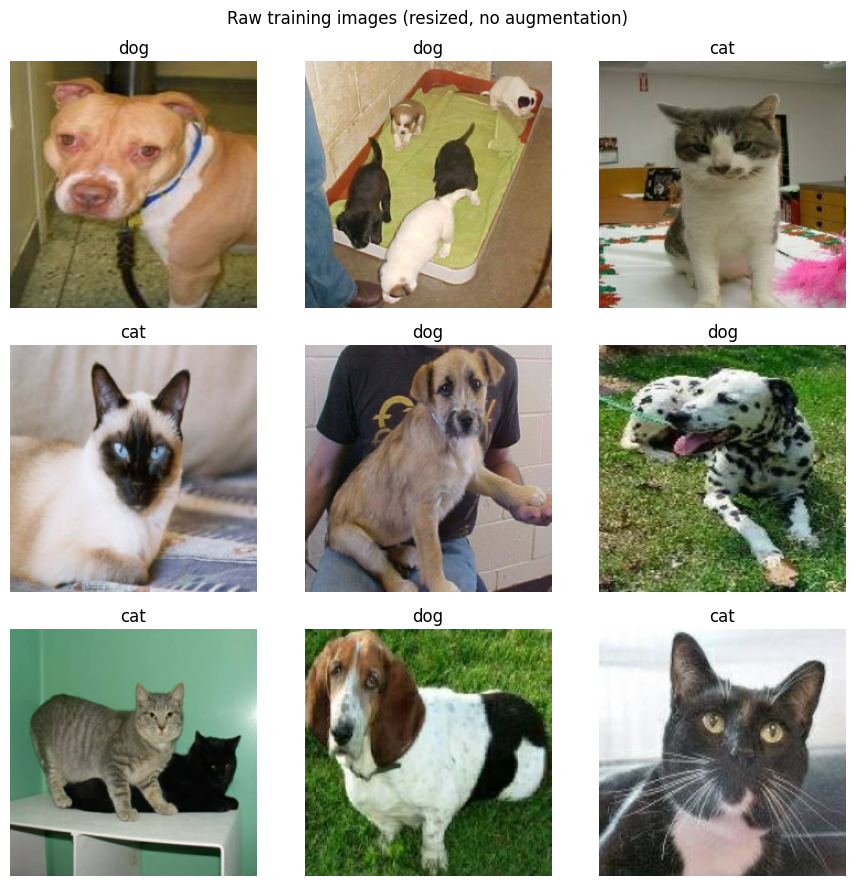

In [ ]:
sample_idx = random.Random(SEED).sample(range(len(train_paths)), 9)
sample_paths = [train_paths[i] for i in sample_idx]
sample_labels = [train_labels[i] for i in sample_idx]

raw_images = next(iter(build_eval_dataset(sample_paths, normalization="cnn")))

plt.figure(figsize=(9, 9))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(raw_images[i].numpy())
    plt.title(CLASS_NAMES[sample_labels[i]])
    plt.axis("off")
plt.suptitle("Raw training images (resized, no augmentation)")
plt.tight_layout()
plt.show()

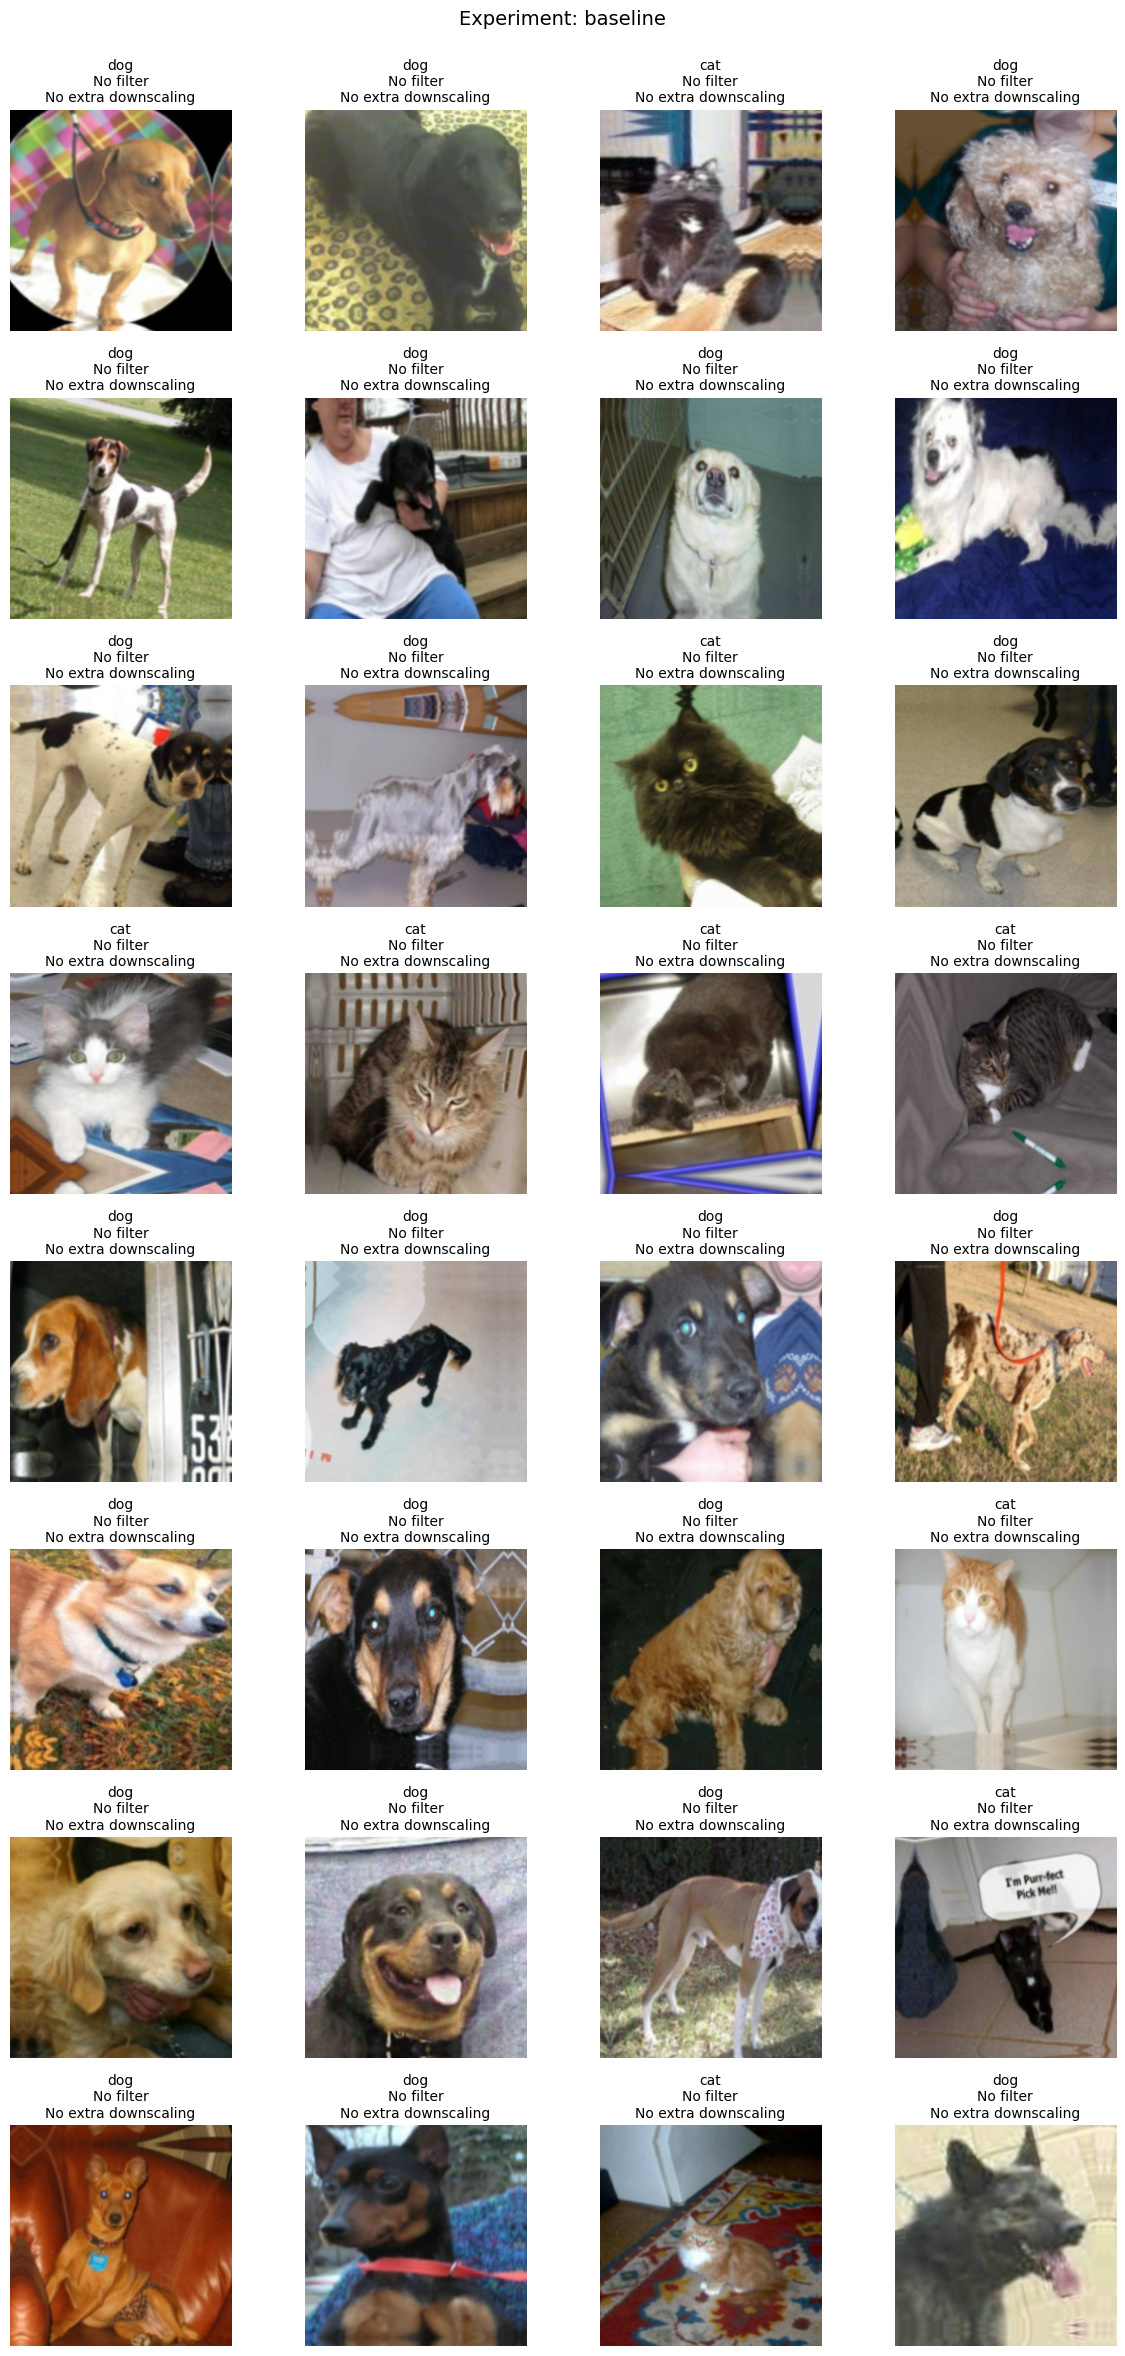

Experiment: baseline
Filter applied: 0/32 images
Extra downscaling: 0/32 images
Image batch shape: (32, 224, 224, 3)


In [ ]:
# Separate preview pipeline with transformation flags
preview_ds = build_training_dataset(train_paths, train_labels, **TRAIN_SETTINGS, debug=True)
images, labels, downscaled, filtered = next(iter(preview_ds))
tf.debugging.assert_all_finite(images, "Images contain invalid values.")

filter_name = {
    "baseline": "Filter",
    "median": "Median",
    "laplacian": "Laplacian"
}[EXPERIMENT]

number = int(images.shape[0])
columns = 4
rows = (number + columns - 1) // columns

fig, axes = plt.subplots(
    rows,
    columns,
    figsize=(12, rows * 3),
    squeeze=False
)

for ax in axes.flat:
    ax.axis("off")

for i in range(number):
    image = denormalize_for_display(images[i].numpy(), NORMALIZATION)
    was_filtered = bool(filtered[i].numpy())
    was_downscaled = bool(downscaled[i].numpy())

    filter_status = (
        f"{filter_name} applied"
        if was_filtered else "No filter"
    )

    downscale_status = (
        "Extra downscaling"
        if was_downscaled else "No extra downscaling"
    )

    label = CLASS_NAMES[int(labels[i, 0].numpy())]

    axes.flat[i].imshow(np.clip(image, 0, 1))
    axes.flat[i].set_title(
        f"{label}\n{filter_status}\n{downscale_status}",
        color="green" if was_filtered else "black",
        fontsize=10
    )

fig.suptitle(f"Experiment: {EXPERIMENT}", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

filter_count = int(
    tf.reduce_sum(tf.cast(filtered, tf.int32)).numpy()
)

downscale_count = int(
    tf.reduce_sum(tf.cast(downscaled, tf.int32)).numpy()
)

print("Experiment:", EXPERIMENT)
print(f"Filter applied: {filter_count}/{number} images")
print(f"Extra downscaling: {downscale_count}/{number} images")
print("Image batch shape:", images.shape)

## 7. Models and submission
Model definitions, training and evaluation. `write_submission` predicts the test set and writes `submission.csv` with IDs in numeric order (1 = dog, 0 = cat).

In [ ]:
def write_submission(model, path=SUBMISSION_PATH, threshold=0.5):
    """Predict the test set and write submission.csv (1 = dog, 0 = cat)."""
    probabilities = model.predict(test_ready, verbose=0).reshape(-1)
    predictions = (probabilities >= threshold).astype(int)

    if len(predictions) != len(test_ids):
        raise ValueError("Prediction count does not match the number of test images.")

    with open(path, "w") as f:
        f.write("id,label\n")
        for image_id, label in zip(test_ids, predictions):
            f.write(f"{image_id},{label}\n")

    print(f"Wrote {len(predictions)} rows to {path} "
          f"({predictions.sum()} dogs, {len(predictions) - predictions.sum()} cats)")
    return probabilities

### 7.1 Training utilities
Shared by every model, so each experiment is one function call.

- `run_experiment` seeds everything, builds a fresh training pipeline, trains with early stopping, and appends the result to `results.csv` on Drive.
- Keras labels the Validation-set metrics `val_loss` / `val_accuracy`, because they come from `validation_data`.
- Training accuracy is measured with augmentation and dropout active, so it can sit slightly below Validation accuracy early in training. This is expected.

In [ ]:
for folder in [CHECKPOINT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

INPUT_SHAPE = (*IMAGE_SIZE, 3)


def compile_model(model, learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
                  label_smoothing=LABEL_SMOOTHING):
    model.compile(
        optimizer=keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=weight_decay),
        loss=keras.losses.BinaryCrossentropy(label_smoothing=label_smoothing),
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")],
    )
    return model


def make_callbacks(checkpoint_name):
    return [
        # Stop when validation loss stops improving, and keep the best epoch's weights.
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=EARLY_STOP_PATIENCE,
            restore_best_weights=True, verbose=1),
        # Halve the learning rate when progress stalls.
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=LR_PATIENCE,
            min_lr=MIN_LR, verbose=1),
        # Save the best model to Drive, so it survives a Colab disconnect.
        keras.callbacks.ModelCheckpoint(
            str(CHECKPOINT_DIR / f"{checkpoint_name}.keras"),
            monitor="val_loss", save_best_only=True),
    ]


def log_result(record, path=RESULTS_PATH):
    row = pd.DataFrame([record])
    if path.exists():
        row = pd.concat([pd.read_csv(path), row], ignore_index=True)
    row.to_csv(path, index=False)

def make_augmentation(settings, seed):
    """Geometric augmentation as model layers, so it runs on the GPU.
    Keras applies these only during training; evaluate() and predict()
    pass images through unchanged."""
    aug = []
    if settings["flipping"]:
        aug.append(layers.RandomFlip("horizontal", seed=seed))

    if settings["rotation"]:
        aug.append(layers.RandomRotation(settings["rotation_factor"],
                                         fill_mode="reflect", seed=seed + 1))
    if settings["zoom"]:
        z = settings["zoom_factor"]
        aug.append(layers.RandomZoom((-z, z), fill_mode="reflect", seed=seed + 4))

    if settings["translation"]:
        t = settings["translation_factor"]
        aug.append(layers.RandomTranslation(t, t, fill_mode="reflect", seed=seed + 5))

    return keras.Sequential(aug, name="augmentation") if aug else None


def run_experiment(build_model, run_name, seed=SEED, train_settings=None,
                   epochs=EPOCHS, verbose=1, **compile_kwargs):

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)   # weight initialization, dropout, shuffling

    settings = dict(TRAIN_SETTINGS if train_settings is None else train_settings, seed=seed)
    if settings["normalization"] != NORMALIZATION:
        raise ValueError("train_settings normalization must match NORMALIZATION "
                         "(the val/test pipelines use NORMALIZATION).")

    # Geometric augmentation runs on the GPU inside the model; the pipeline keeps
    # only the per-image steps (downscaling, median/Laplacian filters).
    pipeline_settings = dict(settings, flipping=False, rotation=False,
                             zoom=False, translation=False)
    train_ds = build_training_dataset(train_paths, train_labels, **pipeline_settings)

    base_model = build_model()
    augmentation = make_augmentation(settings, seed)
    if augmentation is not None:
        model = keras.Sequential([keras.Input(INPUT_SHAPE), augmentation, base_model],
                                 name=base_model.name)
    else:
        model = base_model
    model = compile_model(model, **compile_kwargs)

    start = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ready,
        epochs=epochs,
        callbacks=make_callbacks(f"{run_name}_s{seed}"),
        shuffle=False,   # train_ds already reshuffles every epoch
        verbose=verbose,
    )
    train_minutes = (time.time() - start) / 60

    val = model.evaluate(val_ready, verbose=0, return_dict=True)   # best epoch's weights

    record = {
        "timestamp": time.strftime("%Y-%m-%d %H:%M"),
        "run_name": run_name,
        "seed": seed,
        "model": model.name,
        "params": model.count_params(),
        "image_size": IMAGE_SIZE[0],
        "train_images": len(train_paths),
        "experiment": settings["experiment"],
        "learning_rate": compile_kwargs.get("learning_rate", LEARNING_RATE),
        "weight_decay": compile_kwargs.get("weight_decay", WEIGHT_DECAY),
        "label_smoothing": compile_kwargs.get("label_smoothing", LABEL_SMOOTHING),
        "epochs_run": len(history.history["loss"]),
        "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
        "train_minutes": round(train_minutes, 2),
        "val_loss": round(val["loss"], 4),
        "val_acc": round(val["accuracy"], 4),
        "val_auc": round(val["auc"], 4),
        "augmentation": str({k: v for k, v in settings.items() if k != "seed"}),
    }
    log_result(record)
    print(f"\n{run_name} (seed {seed}): val acc {record['val_acc']:.4f}, "
          f"best epoch {record['best_epoch']}, {record['train_minutes']} min")
    return model, history, record


def plot_history(history, title, save=True):
    """Training vs validation curves for loss and accuracy."""
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, key, label in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(epochs, h[key], label="train")
        ax.plot(epochs, h[f"val_{key}"], label="validation")
        ax.axvline(best, color="grey", linestyle="--", label=f"best epoch ({best})")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    if save:
        fig.savefig(FIGURE_DIR / f"{title}.png", dpi=150)
    plt.show()


def summarize_results(path=RESULTS_PATH, metrics=("val_acc", "val_auc")):
    """Mean, std and run count per configuration (run_name)."""
    df = pd.read_csv(path)
    present = [m for m in metrics if m in df and df[m].notna().any()]
    return df.groupby("run_name")[present].agg(["mean", "std", "count"]).round(4)

### 7.2 VGG-style baseline
Stacks of 3×3 convolutions (Conv → BatchNorm → ReLU, twice per block), with max pooling halving the image after each block and the filter count doubling: 32 → 64 → 128 → 256.

- **Head:** `"gap"` averages each feature map to one number (no parameters); `"flatten"` keeps every value and adds a Dense layer (millions of parameters). Comparing the two is an overfitting ablation.
- **Output:** one sigmoid unit giving P(dog), trained with binary cross-entropy. It stays float32 under mixed precision for a numerically stable loss.
- **Initialization:** He normal, designed for ReLU networks; `"glorot_uniform"` is the Keras default for comparison.

In [ ]:
def build_vgg_baseline(
    input_shape=INPUT_SHAPE,
    filters=CONV_FILTERS,
    convs_per_block=CONVS_PER_BLOCK,
    use_batchnorm=USE_BATCHNORM,
    head=HEAD,
    dense_units=DENSE_UNITS,
    dropout=DROPOUT,
    kernel_init=KERNEL_INIT,
    name="vgg_baseline",
):
    if head not in {"gap", "flatten"}:
        raise ValueError("head must be 'gap' or 'flatten'.")

    model = keras.Sequential(name=name)
    model.add(keras.Input(shape=input_shape))

    for block, n_filters in enumerate(filters, start=1):
        for conv in range(1, convs_per_block + 1):
            # Bias is redundant when BatchNorm follows: BN adds its own shift.
            model.add(layers.Conv2D(
                n_filters, 3, padding="same",
                use_bias=not use_batchnorm,
                kernel_initializer=kernel_init,
                name=f"block{block}_conv{conv}"))
            if use_batchnorm:
                model.add(layers.BatchNormalization(name=f"block{block}_bn{conv}"))
            model.add(layers.ReLU(name=f"block{block}_relu{conv}"))
        model.add(layers.MaxPooling2D(2, name=f"block{block}_pool"))

    if head == "gap":
        model.add(layers.GlobalAveragePooling2D(name="gap"))
    else:
        model.add(layers.Flatten(name="flatten"))
        model.add(layers.Dense(dense_units, activation="relu",
                               kernel_initializer=kernel_init, name="dense"))

    model.add(layers.Dropout(dropout, name="dropout"))
    model.add(layers.Dense(1, activation="sigmoid", dtype="float32", name="output"))
    return model

Model: "vgg_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn1 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu1 (ReLU)             │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_bn2 (BatchNormalization) │ (None, 224, 224, 32)   │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_relu2 (ReLU)             │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn1 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu1 (ReLU)             │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_bn2 (BatchNormalization) │ (None, 112, 112, 64)   │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_relu2 (ReLU)             │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn1 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu1 (ReLU)             │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_bn2 (BatchNormalization) │ (None, 56, 56, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_relu2 (ReLU)             │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_bn1 (BatchNormalization) │ (None, 28, 28, 256)    │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_relu1 (ReLU)             │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 256)    │       589,82

 Total params: 1,175,393 (4.48 MB)

 Trainable params: 1,173,473 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

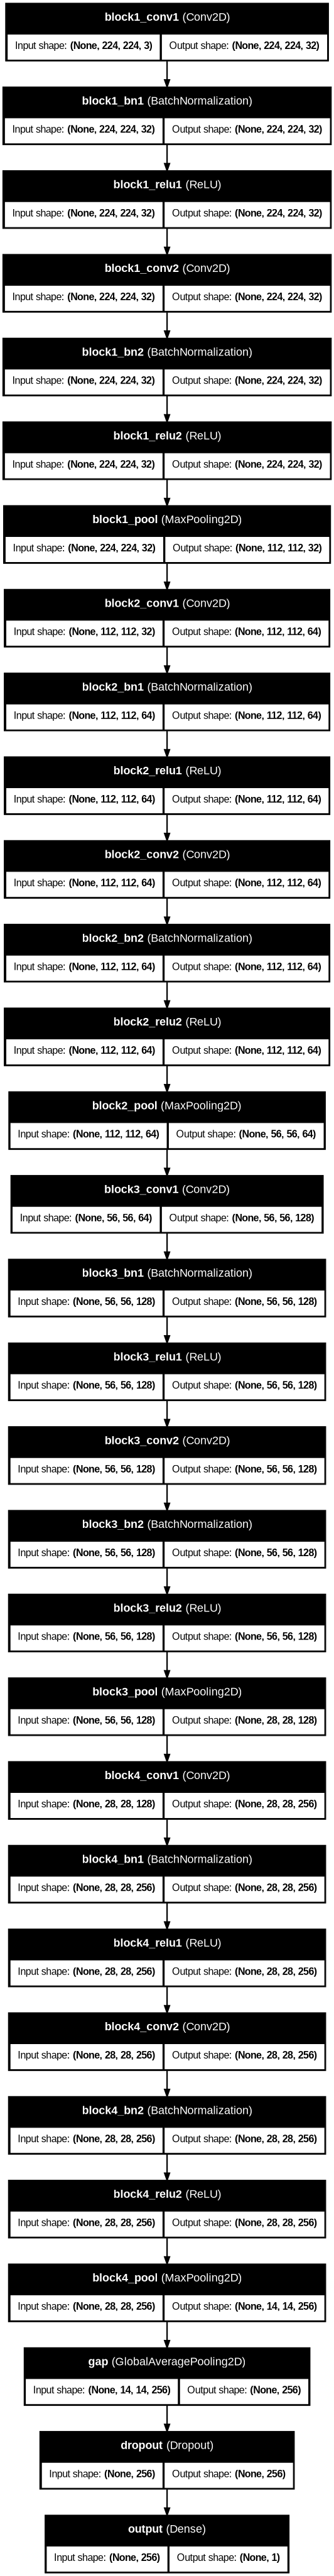

In [ ]:
#Architecture summary and diagram (figure for part b)
baseline_preview = build_vgg_baseline()
baseline_preview.summary()

diagram_path = FIGURE_DIR / "vgg_baseline_architecture.png"
try:
    keras.utils.plot_model(baseline_preview, to_file=str(diagram_path),
                           show_shapes=True, show_layer_names=True, dpi=80)
    display(Image(filename=str(diagram_path)))
except Exception as error:
    print("Diagram skipped (plot_model needs pydot and graphviz):", error)

### 7.3 Train the baseline
One run with the settings from Section 1. The model, curves and results row are saved to Drive.

Epoch 1/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 105s 373ms/step - accuracy: 0.5888 - auc: 0.6226 - loss: 0.7139 - val_accuracy: 0.5755 - val_auc: 0.6389 - val_loss: 0.6920 - learning_rate: 5.0000e-04
Epoch 2/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 50s 317ms/step - accuracy: 0.6174 - auc: 0.6656 - loss: 0.6721 - val_accuracy: 0.6410 - val_auc: 0.6965 - val_loss: 0.6540 - learning_rate: 5.0000e-04
Epoch 3/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 50s 318ms/step - accuracy: 0.6398 - auc: 0.6889 - loss: 0.6596 - val_accuracy: 0.4905 - val_auc: 0.5494 - val_loss: 0.9651 - learning_rate: 5.0000e-04
Epoch 4/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 50s 318ms/step - accuracy: 0.6486 - auc: 0.7049 - loss: 0.6484 - val_accuracy: 0.6890 - val_auc: 0.7587 - val_loss: 0.6424 - learning_rate: 5.0000e-04
Epoch 5/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 50s 318ms/step - accuracy: 0.6876 - auc: 0.7467 - loss: 0.6227 - val_accuracy: 0.6480 - val_auc: 0.7350 - val_loss: 0.6516 - learning_rate: 5.0000e-04
Epoch 6/50
157/157 ━━━━━━━━━━━━━━━━━━━━ 50s 

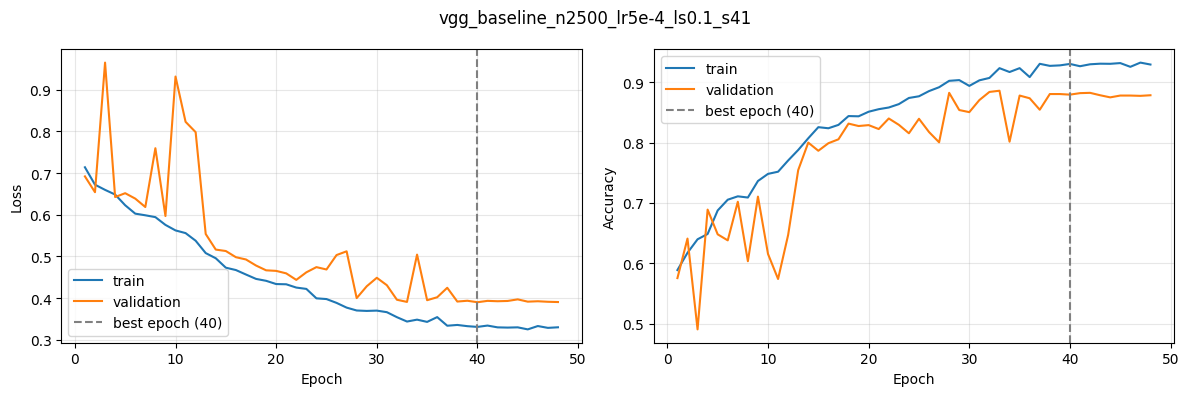

In [ ]:
baseline_model, baseline_history, baseline_record = run_experiment(
    build_vgg_baseline, run_name=RUN_NAME)

plot_history(baseline_history, f"{RUN_NAME}_s{SEED}")

### 7.4 Repeat over seeds
Off by default so *Run all* doesn't start several long training runs. Set `RUN_SEED_SWEEP = True` to repeat a configuration over three seeds and report mean ± std.

In [ ]:
RUN_SEED_SWEEP = False
SWEEP_SEEDS = [41, 42, 43]

if RUN_SEED_SWEEP:
    for seed in SWEEP_SEEDS:
        if seed == SEED:
            continue   # already trained above
        run_experiment(build_vgg_baseline, run_name=RUN_NAME, seed=seed, verbose=0)

summarize_results()

val_acc           val_auc          
                                   mean std count    mean std count
run_name                                                           
vgg_baseline                     0.7840 NaN     1  0.8578 NaN     1
vgg_baseline_n1000               0.7800 NaN     1  0.8547 NaN     1
vgg_baseline_n2500               0.8530 NaN     1  0.9256 NaN     1
vgg_baseline_n2500_lr5e-4        0.8575 NaN     1  0.9315 NaN     1
vgg_baseline_n2500_lr5e-4_ls0.1  0.8795 NaN     1  0.9548 NaN     1